nba mvp prediction code

In [1]:
from nba_api.stats.endpoints import playergamelog, teamgamelog, leaguestandings
from nba_api.stats.static import teams
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import time

In [2]:
#fetching player data
player_ids = {
    'Wembanyama':      '1641706',
    'SGA':             '1628983',
    'Jokic':           '203999',
    'Luka Doncic':     '1629029',
    'Jaylen Brown':    '1627759',
    'Cade Cunningham': '1630595',
}

# Map players to their team abbreviations
player_teams = {
    'Wembanyama':      'SAS',
    'SGA':             'OKC',
    'Jokic':           'DEN',
    'Luka Doncic':     'LAL',
    'Jaylen Brown':    'BOS',
    'Cade Cunningham': 'DET',
}

dfs = []
for player_name, player_id in player_ids.items():
    gamelog = playergamelog.PlayerGameLog(
        player_id=player_id,
        season='2025-26'
    )
    df = gamelog.get_data_frames()[0]
    df['PLAYER_NAME'] = player_name
    dfs.append(df)
    time.sleep(0.6)  # avoid rate limiting

df_stats = pd.concat(dfs, ignore_index=True)
df_stats['MIN'] = pd.to_numeric(df_stats['MIN'], errors='coerce')
print(f"Total rows fetched: {df_stats.shape}")
df_stats.head()

Total rows fetched: (397, 28)


,SEASON_ID,Player_ID,Game_ID,GAME_DATE,MATCHUP,WL,MIN,FGM,FGA,FG_PCT,...,REB,AST,STL,BLK,TOV,PF,PTS,PLUS_MINUS,VIDEO_AVAILABLE,PLAYER_NAME
0,22025,1641706,0022501190,"Apr 12, 2026",CHA @ NYK,W,27,5,12,0.417,...,3,2,1,1,3,3,19,8,1,Wembanyama
1,22025,1641706,0022501171,"Apr 10, 2026",CHA vs. DET,L,31,9,20,0.450,...,3,0,4,0,1,4,22,-8,1,Wembanyama
2,22025,1641706,0022501149,"Apr 07, 2026",CHA @ BOS,L,34,8,16,0.500,...,0,2,0,0,0,2,20,-1,1,Wembanyama
3,22025,1641706,0022501137,"Apr 05, 2026",CHA @ MIN,W,34,3,15,0.200,...,6,3,1,0,1,0,7,22,1,Wembanyama
4,22025,1641706,0022501120,"Apr 03, 2026",CHA vs. IND,W,30,9,17,0.529,...,6,3,1,1,0,2,22,10,1,Wembanyama


In [3]:
#Wembanyama's diagonstic to get accurate statistics
df_wemby = df_stats[df_stats['PLAYER_NAME'] == 'Wembanyama']

print(f"Games played:              {len(df_wemby)}")
print(f"Date range:                {df_wemby['GAME_DATE'].min()} → {df_wemby['GAME_DATE'].max()}")
print(f"Avg PTS (all games):       {df_wemby['PTS'].mean():.2f}")
print(f"Avg MIN (all games):       {df_wemby['MIN'].mean():.2f}")
print("─" * 50)

df_wemby_healthy = df_wemby[df_wemby['MIN'] >= 20]
print(f"Healthy games (20+ min):   {len(df_wemby_healthy)}")
print(f"Avg PTS (healthy games):   {df_wemby_healthy['PTS'].mean():.2f}")
print("─" * 50)

print("\nGame-by-game breakdown (most recent first):")
print(df_wemby[['GAME_DATE','PTS','REB','AST','BLK','MIN']].to_string(index=False))

Games played:              65
Date range:                Apr 02, 2026 → Oct 25, 2025
Avg PTS (all games):       20.17
Avg MIN (all games):       30.29
──────────────────────────────────────────────────
Healthy games (20+ min):   63
Avg PTS (healthy games):   20.65
──────────────────────────────────────────────────

Game-by-game breakdown (most recent first):
   GAME_DATE  PTS  REB  AST  BLK  MIN
Apr 12, 2026   19    3    2    1   27
Apr 10, 2026   22    3    0    0   31
Apr 07, 2026   20    0    2    0   34
Apr 05, 2026    7    6    3    0   34
Apr 03, 2026   22    6    3    1   30
Apr 02, 2026   17    4    4    0   31
Mar 31, 2026   25    1    3    1   29
Mar 29, 2026   13    6    4    0   32
Mar 28, 2026   29    8    0    0   34
Mar 26, 2026   21    8    3    0   33
Mar 24, 2026   13    3    6    0   27
Mar 21, 2026   22    5    3    1   30
Mar 19, 2026   25    4    8    0   28
Mar 17, 2026   16    2    2    0   26
Mar 14, 2026    6    6    3    0   33
Mar 11, 2026   20    3    5    

In [4]:
# clean data
# Filter out games under 20 minutes for ALL players
# removes injury returns, blowouts, and garbage time
df_clean = df_stats[df_stats['MIN'] >= 20].copy()

print("Games per player after filtering:")
print(df_clean['PLAYER_NAME'].value_counts())


Games per player after filtering:
PLAYER_NAME
Jaylen Brown       70
SGA                68
Wembanyama         63
Jokic              63
Luka Doncic        63
Cade Cunningham    63
Name: count, dtype: int64


In [5]:
#Compute Averages, Weighted Efficiency & Consistency
# Base averages
avg = df_clean.groupby('PLAYER_NAME')[['PTS','AST','REB','STL','BLK','TOV','MIN']].mean().reset_index()

# Original efficiency
avg['EFFICIENCY'] = (
    avg['PTS'] + avg['AST'] + avg['REB'] + avg['STL'] + avg['BLK'] - avg['TOV']
) / avg['MIN']

# Weighted efficiency — stats weighted by real basketball value
avg['WEIGHTED_EFF'] = (
    avg['PTS'] * 1.0  +
    avg['AST'] * 1.5  +
    avg['REB'] * 1.2  +
    avg['STL'] * 2.0  +
    avg['BLK'] * 2.0  +
    avg['TOV'] * -1.5
) / avg['MIN']

# Consistency — std dev of points (lower = more consistent)
std = df_clean.groupby('PLAYER_NAME')['PTS'].std().reset_index()
std.columns = ['PLAYER_NAME', 'PTS_STD']

# Normalize consistency: higher score = more consistent
std['CONSISTENCY'] = 1 - (
    (std['PTS_STD'] - std['PTS_STD'].min()) /
    (std['PTS_STD'].max() - std['PTS_STD'].min())
)

avg = avg.merge(std, on='PLAYER_NAME')
avg = avg.sort_values('WEIGHTED_EFF', ascending=False).reset_index(drop=True)

print(avg[['PLAYER_NAME','PTS','AST','REB','STL','BLK','TOV','MIN',
           'EFFICIENCY','WEIGHTED_EFF','CONSISTENCY']].to_string(index=False))

    PLAYER_NAME       PTS       AST       REB      STL      BLK      TOV       MIN  EFFICIENCY  WEIGHTED_EFF  CONSISTENCY
          Jokic 27.857143 10.920635 13.063492 1.460317 0.825397 3.825397 35.365079    1.422352      1.661176     0.000000
    Luka Doncic 33.857143  8.380952  7.793651 1.666667 0.539683 3.968254 36.142857    1.335529      1.500747     0.071042
            SGA 31.132353  6.588235  4.294118 1.397059 0.764706 2.220588 33.250000    1.261831      1.418355     0.642367
Cade Cunningham 24.206349 10.063492  5.603175 1.444444 0.857143 3.730159 34.396825    1.117674      1.309229     0.164338
   Jaylen Brown 29.000000  5.100000  7.000000 1.014286 0.385714 3.671429 34.671429    1.119901      1.221261     0.668645
     Wembanyama 20.650794  3.380952  5.000000 1.047619 0.666667 2.507937 30.809524    0.916538      1.018805     1.000000


In [6]:
standings = leaguestandings.LeagueStandings(season='2025-26').get_data_frames()[0]
print(standings.columns.tolist())
print(standings.head(3))

['LeagueID', 'SeasonID', 'TeamID', 'TeamCity', 'TeamName', 'Conference', 'ConferenceRecord', 'PlayoffRank', 'ClinchIndicator', 'Division', 'DivisionRecord', 'DivisionRank', 'WINS', 'LOSSES', 'WinPCT', 'LeagueRank', 'Record', 'HOME', 'ROAD', 'L10', 'Last10Home', 'Last10Road', 'OT', 'ThreePTSOrLess', 'TenPTSOrMore', 'LongHomeStreak', 'strLongHomeStreak', 'LongRoadStreak', 'strLongRoadStreak', 'LongWinStreak', 'LongLossStreak', 'CurrentHomeStreak', 'strCurrentHomeStreak', 'CurrentRoadStreak', 'strCurrentRoadStreak', 'CurrentStreak', 'strCurrentStreak', 'ConferenceGamesBack', 'DivisionGamesBack', 'ClinchedConferenceTitle', 'ClinchedDivisionTitle', 'ClinchedPlayoffBirth', 'EliminatedConference', 'EliminatedDivision', 'AheadAtHalf', 'BehindAtHalf', 'TiedAtHalf', 'AheadAtThird', 'BehindAtThird', 'TiedAtThird', 'Score100PTS', 'OppScore100PTS', 'OppOver500', 'LeadInFGPCT', 'LeadInReb', 'FewerTurnovers', 'PointsPG', 'OppPointsPG', 'DiffPointsPG', 'vsEast', 'vsAtlantic', 'vsCentral', 'vsSoutheast

In [7]:
#Fetch Team Win %
standings = leaguestandings.LeagueStandings(season='2025-26').get_data_frames()[0]

# Check what we're working with
print("Available columns:", standings.columns.tolist())

# Map players to their full team name as it appears in NBA data
team_name_map = {
    'Wembanyama':      'Spurs',
    'SGA':             'Thunder',
    'Jokic':           'Nuggets',
    'Luka Doncic':     'Lakers',
    'Jaylen Brown':    'Celtics',
    'Cade Cunningham': 'Pistons',
}

win_pct_map = {}
for player, team_name in team_name_map.items():
    # Search across both TeamName and TeamCity columns
    match = standings[
        standings['TeamName'].str.contains(team_name, case=False, na=False) |
        standings['TeamCity'].str.contains(team_name, case=False, na=False)
    ]
    if not match.empty:
        win_pct_map[player] = float(match['WinPCT'].values[0])
        print(f"✓ {player}: {match['WinPCT'].values[0]}")
    else:
        print(f"✗ Could not find team for {player}")

avg['WIN_PCT'] = avg['PLAYER_NAME'].map(win_pct_map)
print("\nFinal win % mapping:")
print(avg[['PLAYER_NAME', 'WIN_PCT']])

Available columns: ['LeagueID', 'SeasonID', 'TeamID', 'TeamCity', 'TeamName', 'Conference', 'ConferenceRecord', 'PlayoffRank', 'ClinchIndicator', 'Division', 'DivisionRecord', 'DivisionRank', 'WINS', 'LOSSES', 'WinPCT', 'LeagueRank', 'Record', 'HOME', 'ROAD', 'L10', 'Last10Home', 'Last10Road', 'OT', 'ThreePTSOrLess', 'TenPTSOrMore', 'LongHomeStreak', 'strLongHomeStreak', 'LongRoadStreak', 'strLongRoadStreak', 'LongWinStreak', 'LongLossStreak', 'CurrentHomeStreak', 'strCurrentHomeStreak', 'CurrentRoadStreak', 'strCurrentRoadStreak', 'CurrentStreak', 'strCurrentStreak', 'ConferenceGamesBack', 'DivisionGamesBack', 'ClinchedConferenceTitle', 'ClinchedDivisionTitle', 'ClinchedPlayoffBirth', 'EliminatedConference', 'EliminatedDivision', 'AheadAtHalf', 'BehindAtHalf', 'TiedAtHalf', 'AheadAtThird', 'BehindAtThird', 'TiedAtThird', 'Score100PTS', 'OppScore100PTS', 'OppOver500', 'LeadInFGPCT', 'LeadInReb', 'FewerTurnovers', 'PointsPG', 'OppPointsPG', 'DiffPointsPG', 'vsEast', 'vsAtlantic', 'vsCen

In [8]:
#Rolling 10-Game Trend
# Assign game number per player (1 = most recent)
df_clean = df_clean.copy()
df_clean['GAME_DATE'] = pd.to_datetime(df_clean['GAME_DATE'])
df_clean = df_clean.sort_values(['PLAYER_NAME', 'GAME_DATE'])
df_clean['GAME_NUM'] = df_clean.groupby('PLAYER_NAME').cumcount() + 1

# Rolling 10-game average PTS
df_clean['ROLLING_PTS'] = df_clean.groupby('PLAYER_NAME')['PTS'].transform(
    lambda x: x.rolling(10, min_periods=1).mean()
)

# Trend score = average PTS in last 10 games
recent_trend = (
    df_clean.groupby('PLAYER_NAME')
    .apply(lambda x: x.nlargest(10, 'GAME_NUM')['PTS'].mean())
    .reset_index()
)
recent_trend.columns = ['PLAYER_NAME', 'TREND_SCORE']

# Normalize trend 0-1
recent_trend['TREND_NORM'] = (
    (recent_trend['TREND_SCORE'] - recent_trend['TREND_SCORE'].min()) /
    (recent_trend['TREND_SCORE'].max() - recent_trend['TREND_SCORE'].min())
)

avg = avg.merge(recent_trend, on='PLAYER_NAME')

print(avg[['PLAYER_NAME', 'TREND_SCORE', 'TREND_NORM']].to_string(index=False))

    PLAYER_NAME  TREND_SCORE  TREND_NORM
          Jokic         25.2    0.396907
    Luka Doncic         36.9    1.000000
            SGA         29.0    0.592784
Cade Cunningham         17.5    0.000000
   Jaylen Brown         30.4    0.664948
     Wembanyama         19.5    0.103093


/var/folders/cc/9kprw1v571bc61lb0vz1_tk40000gn/T/ipykernel_38400/1558517387.py:16: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.nlargest(10, 'GAME_NUM')['PTS'].mean())


In [ ]:
#Composite MVP Score
# Step 1 - rebuild win_pct from standings cleanly and merge into avg
win_df = pd.DataFrame(list(win_pct_map.items()), columns=['PLAYER_NAME', 'WIN_PCT'])

# merge into avg (this is the step that was missing)
avg = avg.merge(win_df, on='PLAYER_NAME', how='left')

# verify it merged correctly before continuing
print("Checking WIN_PCT merged correctly:")
print(avg[['PLAYER_NAME', 'WIN_PCT']])
print()

# Step 2 - normalize all components 0-1
avg['WEFF_NORM'] = (
    (avg['WEIGHTED_EFF'] - avg['WEIGHTED_EFF'].min()) /
    (avg['WEIGHTED_EFF'].max() - avg['WEIGHTED_EFF'].min())
)

avg['WINPCT_NORM'] = (
    (avg['WIN_PCT'] - avg['WIN_PCT'].min()) /
    (avg['WIN_PCT'].max() - avg['WIN_PCT'].min())
)

# Step 3 - composite MVP score
avg['MVP_SCORE'] = (
    avg['WEFF_NORM']   * 0.40 +   # weighted performance
    avg['WINPCT_NORM'] * 0.35 +   # team success
    avg['CONSISTENCY'] * 0.15 +   # reliability
    avg['TREND_NORM']  * 0.10     # recent form
)

avg = avg.sort_values('MVP_SCORE', ascending=False).reset_index(drop=True)

print("🏆 MVP SCORE RANKINGS:")
print(avg[['PLAYER_NAME','MVP_SCORE','WEFF_NORM','WINPCT_NORM',
           'CONSISTENCY','TREND_NORM']].to_string(index=False))

Checking WIN_PCT merged correctly:
       PLAYER_NAME  WIN_PCT
0            Jokic    0.659
1      Luka Doncic    0.646
2              SGA    0.780
3  Cade Cunningham    0.732
4     Jaylen Brown    0.683
5       Wembanyama    0.756

🏆 MVP SCORE RANKINGS:
    PLAYER_NAME  MVP_SCORE  WEFF_NORM  WINPCT_NORM  CONSISTENCY  TREND_NORM
            SGA   0.754430   0.621992     1.000000     0.642367    0.592784
          Jokic   0.473646   1.000000     0.097015     0.000000    0.396907
     Wembanyama   0.447623   0.000000     0.820896     1.000000    0.103093
Cade Cunningham   0.430123   0.452113     0.641791     0.164338    0.000000
    Luka Doncic   0.410758   0.750254     0.000000     0.071042    1.000000
   Jaylen Brown   0.389501   0.315170     0.276119     0.668645    0.664948


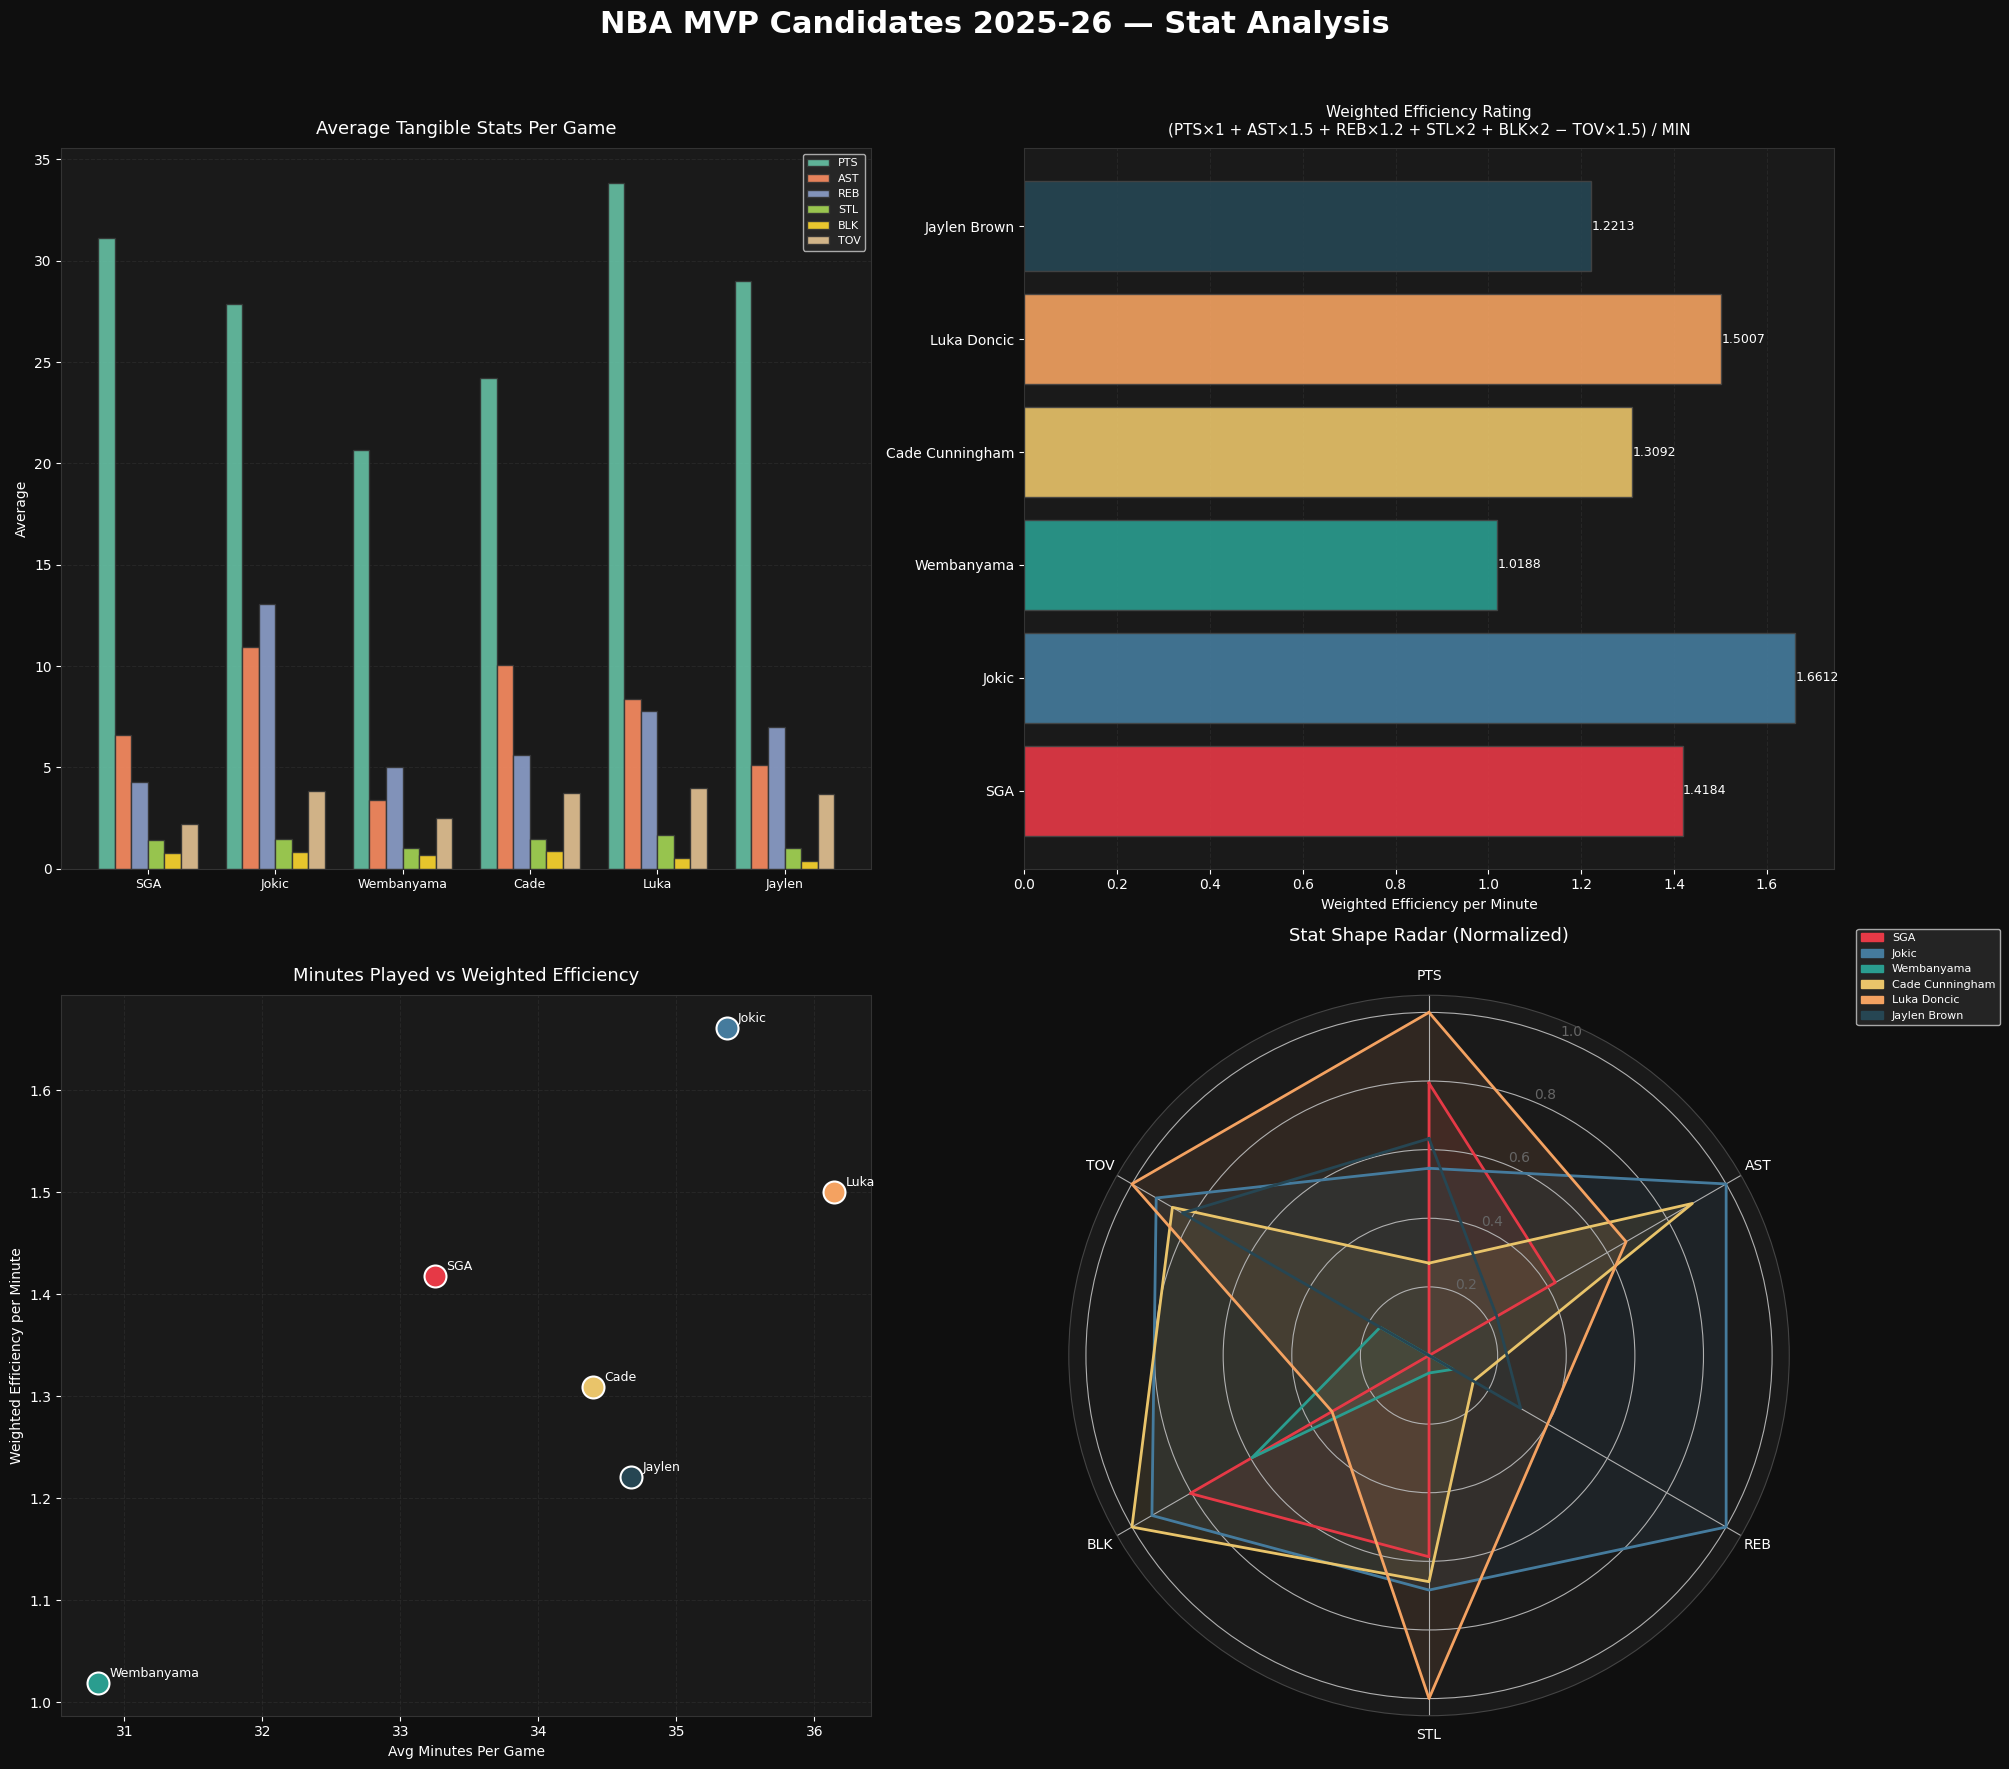

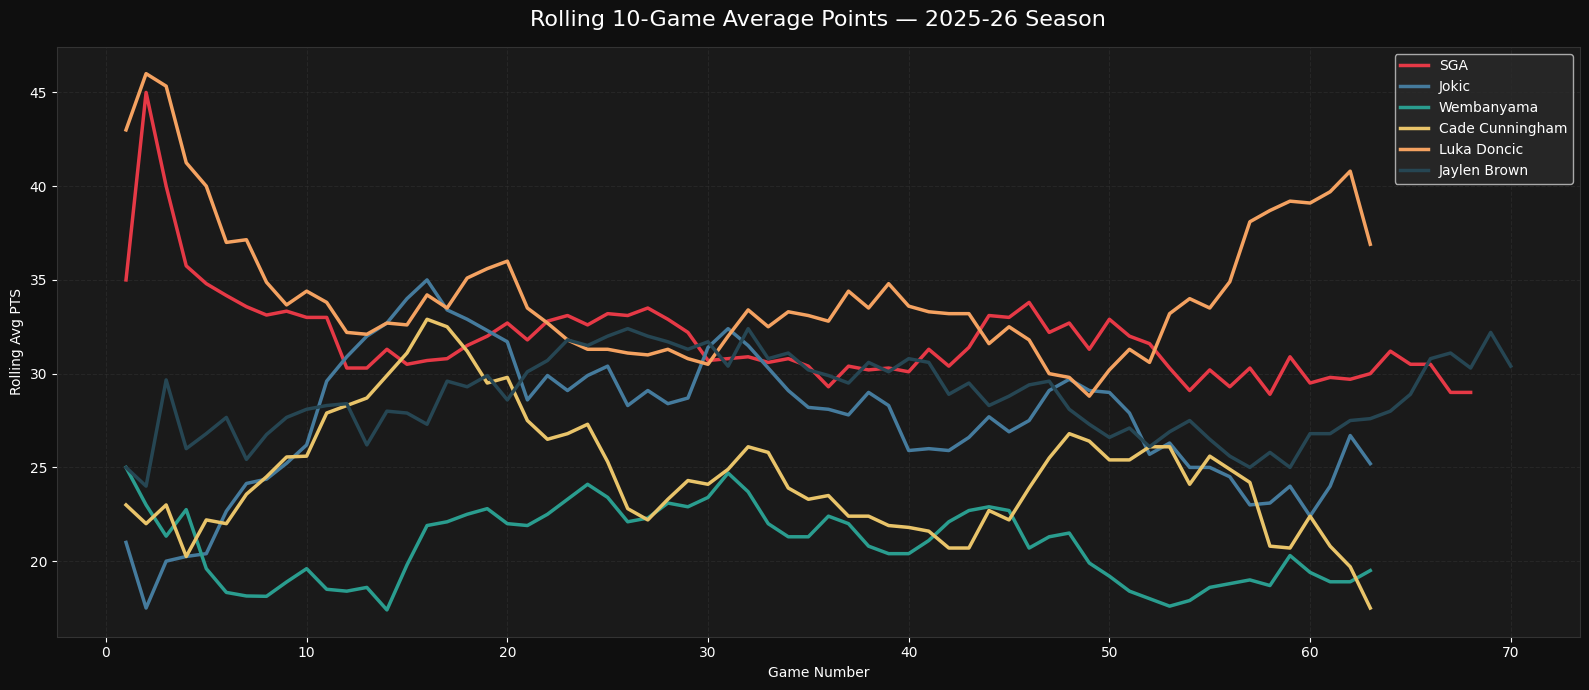

/var/folders/cc/9kprw1v571bc61lb0vz1_tk40000gn/T/ipykernel_38400/1784126403.py:140: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/cc/9kprw1v571bc61lb0vz1_tk40000gn/T/ipykernel_38400/1784126403.py:141: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  plt.savefig('nba_mvp_score_2025_26.png', dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
/Users/sahilsardar/Library/Python/3.13/lib/python/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 127942 (\N{TROPHY}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


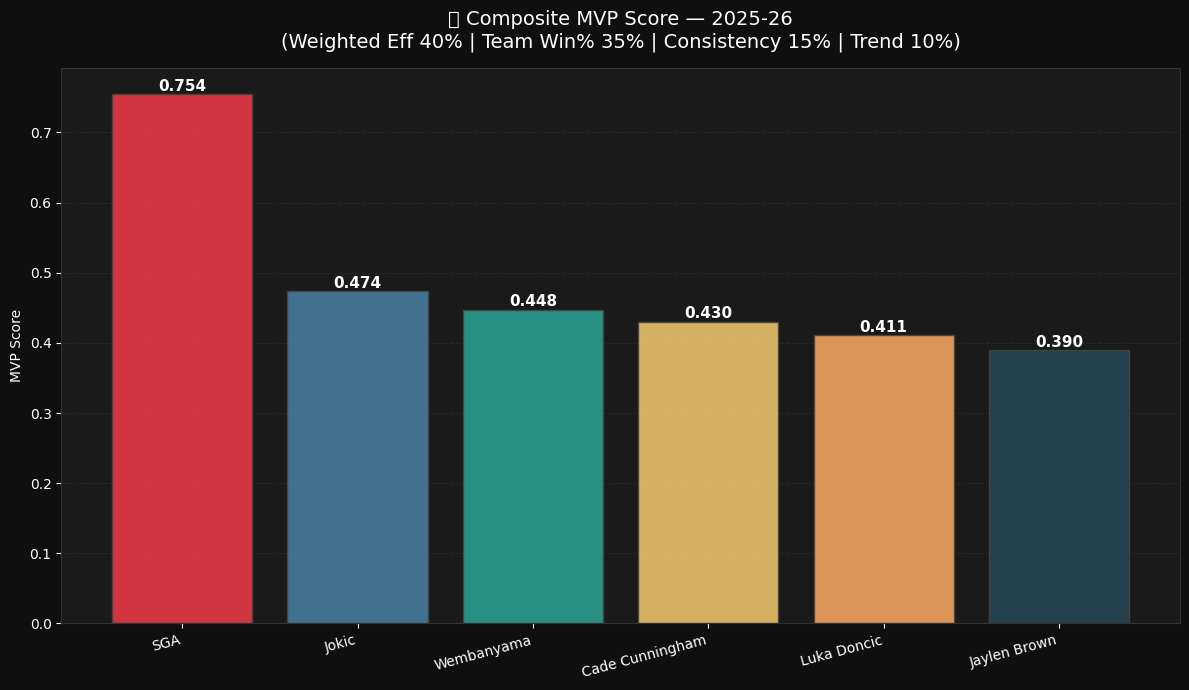

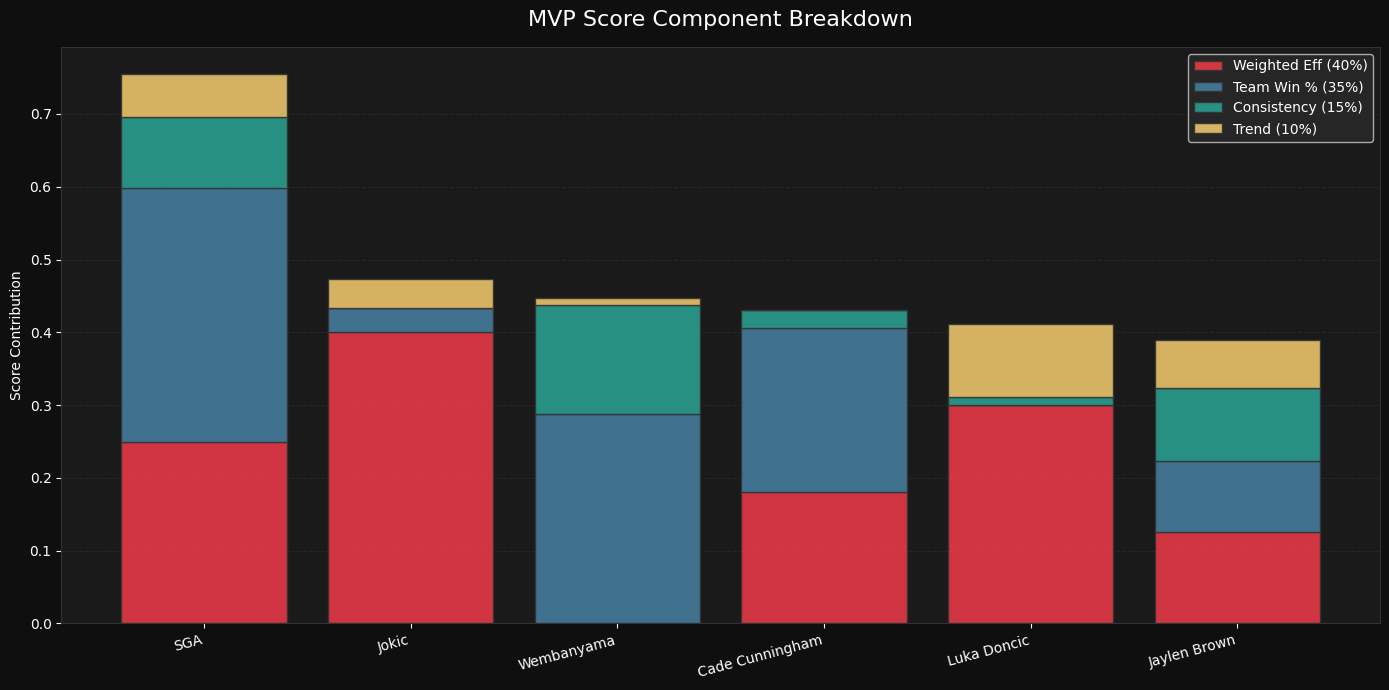

In [11]:
# ── 3. Styling ─────────────────────────────────────────────────────────────────
COLORS = ['#E63946','#457B9D','#2A9D8F','#E9C46A','#F4A261','#264653']
players = avg['PLAYER_NAME'].tolist()
color_map = {p: COLORS[i] for i, p in enumerate(players)}

# ── Figure 1: Original 4 Charts ───────────────────────────────────────────────
fig1 = plt.figure(figsize=(20, 18))
fig1.patch.set_facecolor('#0f0f0f')
plt.suptitle('NBA MVP Candidates 2025-26 — Stat Analysis',
             fontsize=22, fontweight='bold', color='white', y=0.98)

# Chart 1: Grouped Bar — Avg Tangible Stats
ax1 = fig1.add_subplot(2, 2, 1)
ax1.set_facecolor('#1a1a1a')
stat_cols = ['PTS', 'AST', 'REB', 'STL', 'BLK', 'TOV']
x = np.arange(len(players))
width = 0.13
for i, stat in enumerate(stat_cols):
    offset = (i - len(stat_cols) / 2) * width + width / 2
    ax1.bar(x + offset, avg[stat], width, label=stat,
            color=plt.cm.Set2(i / len(stat_cols)), alpha=0.9, edgecolor='#333')
ax1.set_xticks(x)
ax1.set_xticklabels([p.split()[0] for p in players], color='white', fontsize=9)
ax1.set_title('Average Tangible Stats Per Game', color='white', fontsize=13, pad=10)
ax1.set_ylabel('Average', color='white')
ax1.tick_params(colors='white')
ax1.legend(loc='upper right', fontsize=8, facecolor='#2a2a2a', labelcolor='white')
ax1.spines[['top','right','left','bottom']].set_color('#333')
ax1.yaxis.grid(True, color='#333', linestyle='--', alpha=0.5)
ax1.set_axisbelow(True)

# Chart 2: Weighted Efficiency Bar
ax2 = fig1.add_subplot(2, 2, 2)
ax2.set_facecolor('#1a1a1a')
bar_colors = [color_map[p] for p in avg['PLAYER_NAME']]
bars = ax2.barh(avg['PLAYER_NAME'], avg['WEIGHTED_EFF'], color=bar_colors, edgecolor='#444', alpha=0.9)
for bar, val in zip(bars, avg['WEIGHTED_EFF']):
    ax2.text(bar.get_width() + 0.001, bar.get_y() + bar.get_height()/2,
             f'{val:.4f}', va='center', color='white', fontsize=9)
ax2.set_title('Weighted Efficiency Rating\n(PTS×1 + AST×1.5 + REB×1.2 + STL×2 + BLK×2 − TOV×1.5) / MIN',
              color='white', fontsize=11, pad=10)
ax2.set_xlabel('Weighted Efficiency per Minute', color='white')
ax2.tick_params(colors='white')
ax2.spines[['top','right','left','bottom']].set_color('#333')
ax2.xaxis.grid(True, color='#333', linestyle='--', alpha=0.5)
ax2.set_axisbelow(True)

# Chart 3: Minutes vs Efficiency Scatter
ax3 = fig1.add_subplot(2, 2, 3)
ax3.set_facecolor('#1a1a1a')
for _, row in avg.iterrows():
    ax3.scatter(row['MIN'], row['WEIGHTED_EFF'],
                color=color_map[row['PLAYER_NAME']], s=250, zorder=5,
                edgecolors='white', linewidths=1.5)
    ax3.annotate(row['PLAYER_NAME'].split()[0],
                 (row['MIN'], row['WEIGHTED_EFF']),
                 textcoords='offset points', xytext=(8, 4),
                 color='white', fontsize=9)
ax3.set_title('Minutes Played vs Weighted Efficiency', color='white', fontsize=13, pad=10)
ax3.set_xlabel('Avg Minutes Per Game', color='white')
ax3.set_ylabel('Weighted Efficiency per Minute', color='white')
ax3.tick_params(colors='white')
ax3.spines[['top','right','left','bottom']].set_color('#333')
ax3.grid(color='#333', linestyle='--', alpha=0.5)

# Chart 4: Radar Chart
ax4 = fig1.add_subplot(2, 2, 4, polar=True)
ax4.set_facecolor('#1a1a1a')
categories = ['PTS', 'AST', 'REB', 'STL', 'BLK', 'TOV']
N = len(categories)
angles = [n / float(N) * 2 * np.pi for n in range(N)]
angles += angles[:1]
ax4.set_theta_offset(np.pi / 2)
ax4.set_theta_direction(-1)
ax4.set_xticks(angles[:-1])
ax4.set_xticklabels(categories, color='white', size=10)
ax4.tick_params(colors='white')
ax4.spines['polar'].set_color('#444')
for _, row in avg.iterrows():
    vals = [row[c] for c in categories]
    vals_norm = [(v - avg[c].min()) / (avg[c].max() - avg[c].min() + 1e-9)
                 for v, c in zip(vals, categories)]
    vals_norm += vals_norm[:1]
    ax4.plot(angles, vals_norm, color=color_map[row['PLAYER_NAME']], linewidth=2)
    ax4.fill(angles, vals_norm, color=color_map[row['PLAYER_NAME']], alpha=0.1)
legend_patches = [mpatches.Patch(color=color_map[p], label=p) for p in players]
ax4.legend(handles=legend_patches, loc='upper right', bbox_to_anchor=(1.3, 1.1),
           fontsize=8, facecolor='#2a2a2a', labelcolor='white')
ax4.set_title('Stat Shape Radar (Normalized)', color='white', fontsize=13, pad=20)
ax4.yaxis.set_tick_params(labelcolor='#666')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('nba_stats_2025_26.png', dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
plt.show()

# ── Figure 2: Rolling Trend Chart ─────────────────────────────────────────────
fig2, ax = plt.subplots(figsize=(16, 7))
fig2.patch.set_facecolor('#0f0f0f')
ax.set_facecolor('#1a1a1a')

for player in players:
    pdf = df_clean[df_clean['PLAYER_NAME'] == player].sort_values('GAME_DATE')
    ax.plot(pdf['GAME_NUM'], pdf['ROLLING_PTS'],
            color=color_map[player], linewidth=2.5, label=player)

ax.set_title('Rolling 10-Game Average Points — 2025-26 Season',
             color='white', fontsize=16, pad=15)
ax.set_xlabel('Game Number', color='white')
ax.set_ylabel('Rolling Avg PTS', color='white')
ax.tick_params(colors='white')
ax.spines[['top','right','left','bottom']].set_color('#333')
ax.grid(color='#333', linestyle='--', alpha=0.5)
ax.legend(facecolor='#2a2a2a', labelcolor='white', fontsize=10)

plt.tight_layout()
plt.savefig('nba_rolling_trend_2025_26.png', dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
plt.show()

# ── Figure 3: MVP Score Bar Chart ─────────────────────────────────────────────
fig3, ax = plt.subplots(figsize=(12, 7))
fig3.patch.set_facecolor('#0f0f0f')
ax.set_facecolor('#1a1a1a')

mvp_colors = [color_map[p] for p in avg['PLAYER_NAME']]
bars = ax.bar(avg['PLAYER_NAME'], avg['MVP_SCORE'], color=mvp_colors, edgecolor='#444', alpha=0.9)

for bar, val in zip(bars, avg['MVP_SCORE']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{val:.3f}', ha='center', color='white', fontsize=11, fontweight='bold')

ax.set_title('🏆 Composite MVP Score — 2025-26\n(Weighted Eff 40% | Team Win% 35% | Consistency 15% | Trend 10%)',
             color='white', fontsize=14, pad=15)
ax.set_ylabel('MVP Score', color='white')
ax.tick_params(colors='white')
ax.spines[['top','right','left','bottom']].set_color('#333')
ax.yaxis.grid(True, color='#333', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
plt.xticks(rotation=15, ha='right')

plt.tight_layout()
plt.savefig('nba_mvp_score_2025_26.png', dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
plt.show()

# ── Figure 4: Component Breakdown Stacked Bar ─────────────────────────────────
fig4, ax = plt.subplots(figsize=(14, 7))
fig4.patch.set_facecolor('#0f0f0f')
ax.set_facecolor('#1a1a1a')

components = {
    'Weighted Eff (40%)':  avg['WEFF_NORM']   * 0.40,
    'Team Win % (35%)':    avg['WINPCT_NORM']  * 0.35,
    'Consistency (15%)':   avg['CONSISTENCY']  * 0.15,
    'Trend (10%)':         avg['TREND_NORM']   * 0.10,
}
comp_colors = ['#E63946','#457B9D','#2A9D8F','#E9C46A']
bottom = np.zeros(len(avg))

for (label, vals), color in zip(components.items(), comp_colors):
    ax.bar(avg['PLAYER_NAME'], vals, bottom=bottom, label=label,
           color=color, edgecolor='#333', alpha=0.9)
    bottom += vals.values

ax.set_title('MVP Score Component Breakdown',
             color='white', fontsize=16, pad=15)
ax.set_ylabel('Score Contribution', color='white')
ax.tick_params(colors='white')
ax.spines[['top','right','left','bottom']].set_color('#333')
ax.yaxis.grid(True, color='#333', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
ax.legend(facecolor='#2a2a2a', labelcolor='white', fontsize=10)
plt.xticks(rotation=15, ha='right')

plt.tight_layout()
plt.savefig('nba_mvp_breakdown_2025_26.png', dpi=150, bbox_inches='tight', facecolor='#0f0f0f')
plt.show()